In [ ]:
from pathlib import Path
import os
import pandas as pd

# Read the datasets prepared earlier; this notebook does not download or clone.
# In WSL, the default is outside Git and OneDrive. For another location, set
# PLANT_DISEASE_DATA_DIR before starting Jupyter, or edit DATA_ROOT below.
DATA_ROOT = Path(os.environ.get(
    "PLANT_DISEASE_DATA_DIR",
    Path.home() / "datasets" / "cecs551-plant-disease",
)).expanduser().resolve()
PV_ROOT = DATA_ROOT / "plantvillage"
PD_ROOT = DATA_ROOT / "plantdoc"

PV_COLOR_DIR = PV_ROOT / "raw" / "color"
PD_TRAIN_DIR = PD_ROOT / "train"
PD_TEST_DIR = PD_ROOT / "test"

# Keep machine-specific paths in a local text report, not saved notebook output.
# This file is Git-ignored. It records locations; DATA_ROOT above controls them.
PATH_REPORT = Path("dataset-paths.local.txt")
PATH_REPORT.write_text(
    f"PlantVillage image folder: {PV_COLOR_DIR}\n"
    f"PlantDoc train folder: {PD_TRAIN_DIR}\n"
    f"PlantDoc test folder: {PD_TEST_DIR}\n",
    encoding="utf-8",
)

# Stop with setup instructions if the data is missing. Never download silently.
for required in [PV_COLOR_DIR, PD_TRAIN_DIR, PD_TEST_DIR]:
    if not required.is_dir():
        raise FileNotFoundError(
            f"Dataset folder not found: {required.relative_to(DATA_ROOT)}. "
            "See dataset-paths.local.txt for this machine's full paths. "
            "Check DATA_ROOT (or PLANT_DISEASE_DATA_DIR). For a fresh setup, "
            "see docs/data-downloads.md and run python scripts/prepare_data.py "
            "from the project folder with the project Python environment."
        )

print("Dataset folders found. Local paths saved to dataset-paths.local.txt (Git-ignored).")


Dataset folders found. Local paths saved to dataset-paths.local.txt (Git-ignored).


In [ ]:
from collections import Counter
from datetime import date
from IPython.display import display

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}


def image_files(folder):
    """Return supported image paths below a folder, case-insensitively by extension."""
    return sorted(
        path for path in Path(folder).rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )


def index_folder(folder, dataset_name, split_name):
    rows = []
    for path in image_files(folder):
        rows.append({
            "dataset": dataset_name,
            "class_label": path.parent.name,
            "split": split_name,
            "path": str(path),
            "file_size_bytes": path.stat().st_size,
        })
    return pd.DataFrame(rows)

pv_files = index_folder(PV_COLOR_DIR, "PlantVillage", "all")
pd_train_files = index_folder(PD_TRAIN_DIR, "PlantDoc", "train")
pd_test_files = index_folder(PD_TEST_DIR, "PlantDoc", "test")
pd_files = pd.concat([pd_train_files, pd_test_files], ignore_index=True)

if pv_files.empty or pd_files.empty:
    raise RuntimeError("No images were found. Check DATA_ROOT and the dataset preparation instructions.")

pv_classes = sorted(pv_files["class_label"].unique())
pd_classes = sorted(pd_files["class_label"].unique())

print("Checked on:", date.today().isoformat())
print("Downloaded image counts:")
print(f"PlantVillage raw/color: {len(pv_files):,} images across {len(pv_classes)} class folders")
print(f"PlantDoc train: {len(pd_train_files):,}; test: {len(pd_test_files):,}; total: {len(pd_files):,} across {len(pd_classes)} class folders")
pv_bytes = int(pv_files["file_size_bytes"].sum())
pd_bytes = int(pd_files["file_size_bytes"].sum())
print(f"PlantVillage image bytes: {pv_bytes:,}")
print(f"PlantDoc image bytes: {pd_bytes:,}")


def first_existing_local_file(folder, candidates):
    """Read source documentation from extracted folders; no Git checkout needed."""
    for name in candidates:
        path = folder / name
        if path.is_file():
            return name, path.read_text(encoding="utf-8")
    return None, None

pv_license_name, pv_license_text = first_existing_local_file(
    PV_ROOT, ["LICENSE", "LICENSE.txt", "LICENSE.md", "COPYING"]
)
pd_license_name, pd_license_text = first_existing_local_file(
    PD_ROOT, ["LICENSE.txt", "LICENSE", "LICENSE.md", "COPYING"]
)
print("PlantVillage license file found:", pv_license_name or "No root license file found")
print("PlantDoc license file found:", pd_license_name or "No root license file found")
if pd_license_text:
    print("PlantDoc license text (beginning):\n", pd_license_text[:1200])
if pv_license_text:
    print("PlantVillage license text (beginning):\n", pv_license_text[:1200])


pv_count_by_class = Counter(pv_files["class_label"])
pd_count_by_class = Counter(pd_files["class_label"])

# Show every source folder label, exactly as written in the repository.
print("\nPlantVillage folder labels:")
display(pd.DataFrame({"PlantVillage class folder": pv_classes}))
print("PlantDoc folder labels:")
display(pd.DataFrame({"PlantDoc class folder": pd_classes}))


Checked on: 2026-10-30
Downloaded image counts:
PlantVillage raw/color: 54,305 images across 38 class folders
PlantDoc train: 2,342; test: 236; total: 2,578 across 28 class folders
PlantVillage image bytes: 850,785,369
PlantDoc image bytes: 996,322,499
PlantVillage license file found: No root license file found
PlantDoc license file found: LICENSE.txt
PlantDoc license text (beginning):
 Attribution 4.0 International


Creative Commons Corporation ("Creative Commons") is not a law firm and
does not provide legal services or legal advice. Distribution of
Creative Commons public licenses does not create a lawyer-client or
other relationship. Creative Commons makes its licenses and related
information available on an "as-is" basis. Creative Commons gives no
warranties regarding its licenses, any material licensed under their
terms and conditions, or any related information. Creative Commons
disclaims all liability for damages resulting from their use to the
fullest extent possible.

Using 

,PlantVillage class folder
0,Apple___Apple_scab
1,Apple___Black_rot
2,Apple___Cedar_apple_rust
3,Apple___healthy
4,Blueberry___healthy
5,Cherry_(including_sour)___Powdery_mildew
6,Cherry_(including_sour)___healthy
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...
8,Corn_(maize)___Common_rust_
9,Corn_(maize)___Northern_Leaf_Blight


PlantDoc folder labels:


,PlantDoc class folder
0,Apple Scab Leaf
1,Apple leaf
2,Apple rust leaf
3,Bell_pepper leaf
4,Bell_pepper leaf spot
5,Blueberry leaf
6,Cherry leaf
7,Corn Gray leaf spot
8,Corn leaf blight
9,Corn rust leaf


Exploratory comparison: all 27 pairs are proposed, not finalized.
Five broader disease labels still need confirmation; see docs/category-mapping.md.
Corn-blight review: some train/test filenames name other diseases; filenames alone do not prove mislabeling.


,Class,Mapping status,PlantVillage (GitHub total),PlantDoc (GitHub total)
0,Apple Scab,Condition names correspond; proposed,630,93
1,Apple Rust,Needs confirmation,275,89
2,Apple Healthy,Healthy category supported by paper; proposed,1645,91
3,Blueberry Healthy,Healthy category supported by paper; proposed,1502,117
4,Cherry Healthy,Healthy category supported by paper; proposed,854,57
5,Corn Gray leaf spot,Condition names correspond; proposed,513,68
6,Corn Rust,Needs confirmation,1192,116
7,Corn Northern Leaf Blight,Needs confirmation,985,192
8,Grape Black Rot,Condition names correspond; proposed,1180,64
9,Grape Healthy,Healthy category supported by paper; proposed,423,69


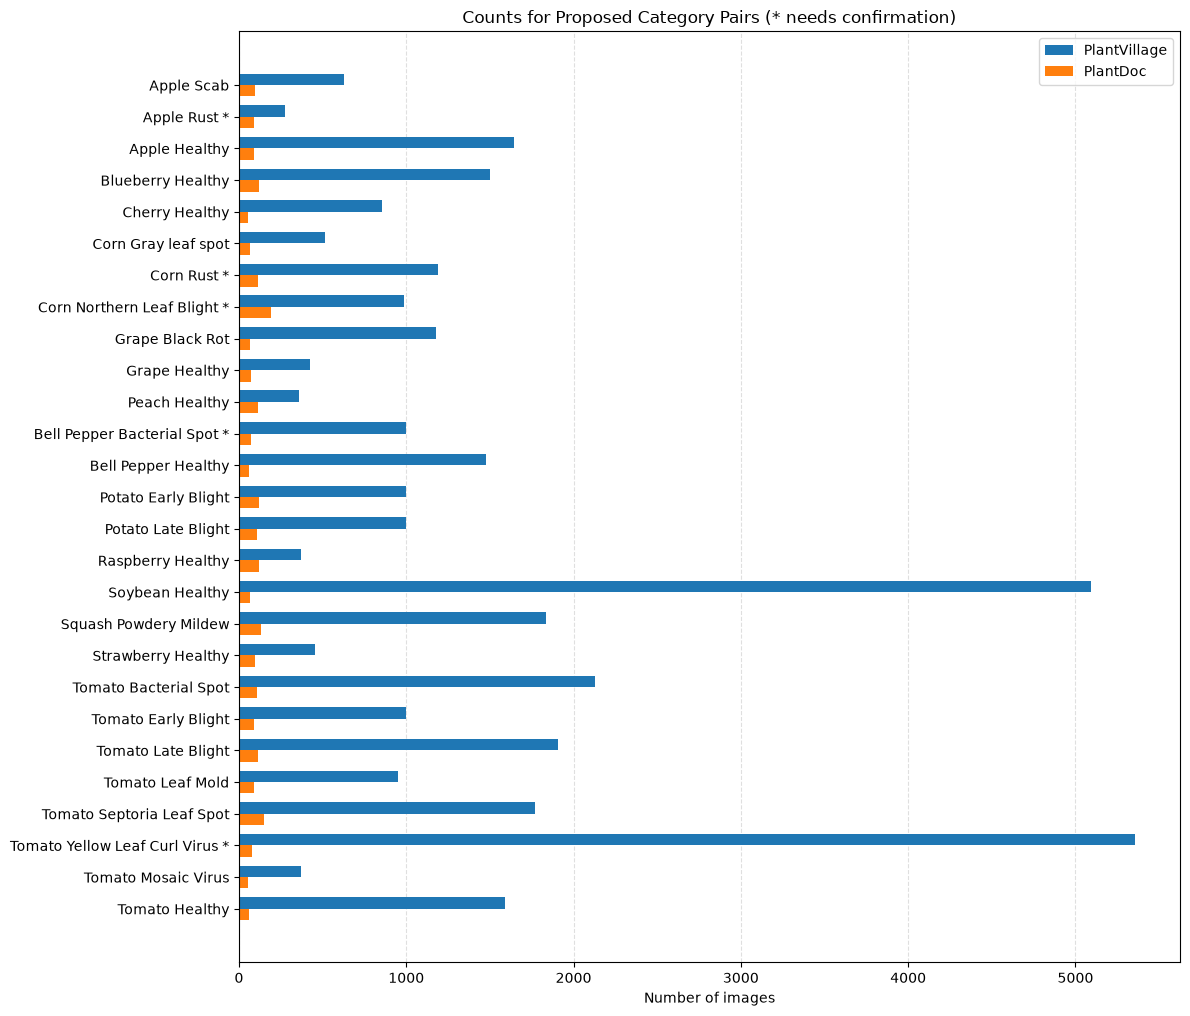

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Proposed pairs for exploratory counts and pictures, not a final training map.
# See ../docs/category-mapping.md for evidence and unresolved label meanings.
class_map = [
    ("Apple Scab", "Apple___Apple_scab", "Apple Scab Leaf"),
    ("Apple Rust", "Apple___Cedar_apple_rust", "Apple rust leaf"),
    ("Apple Healthy", "Apple___healthy", "Apple leaf"),
    ("Blueberry Healthy", "Blueberry___healthy", "Blueberry leaf"),
    ("Cherry Healthy", "Cherry_(including_sour)___healthy", "Cherry leaf"),
    ("Corn Gray leaf spot", "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot", "Corn Gray leaf spot"),
    ("Corn Rust", "Corn_(maize)___Common_rust_", "Corn rust leaf"),
    ("Corn Northern Leaf Blight", "Corn_(maize)___Northern_Leaf_Blight", "Corn leaf blight"),
    ("Grape Black Rot", "Grape___Black_rot", "grape leaf black rot"),
    ("Grape Healthy", "Grape___healthy", "grape leaf"),
    ("Peach Healthy", "Peach___healthy", "Peach leaf"),
    ("Bell Pepper Bacterial Spot", "Pepper,_bell___Bacterial_spot", "Bell_pepper leaf spot"),
    ("Bell Pepper Healthy", "Pepper,_bell___healthy", "Bell_pepper leaf"),
    ("Potato Early Blight", "Potato___Early_blight", "Potato leaf early blight"),
    ("Potato Late Blight", "Potato___Late_blight", "Potato leaf late blight"),
    ("Raspberry Healthy", "Raspberry___healthy", "Raspberry leaf"),
    ("Soybean Healthy", "Soybean___healthy", "Soyabean leaf"),
    ("Squash Powdery Mildew", "Squash___Powdery_mildew", "Squash Powdery mildew leaf"),
    ("Strawberry Healthy", "Strawberry___healthy", "Strawberry leaf"),
    ("Tomato Bacterial Spot", "Tomato___Bacterial_spot", "Tomato leaf bacterial spot"),
    ("Tomato Early Blight", "Tomato___Early_blight", "Tomato Early blight leaf"),
    ("Tomato Late Blight", "Tomato___Late_blight", "Tomato leaf late blight"),
    ("Tomato Leaf Mold", "Tomato___Leaf_Mold", "Tomato mold leaf"),
    ("Tomato Septoria Leaf Spot", "Tomato___Septoria_leaf_spot", "Tomato Septoria leaf spot"),
    ("Tomato Yellow Leaf Curl Virus", "Tomato___Tomato_Yellow_Leaf_Curl_Virus", "Tomato leaf yellow virus"),
    ("Tomato Mosaic Virus", "Tomato___Tomato_mosaic_virus", "Tomato leaf mosaic virus"),
    ("Tomato Healthy", "Tomato___healthy", "Tomato leaf"),
]

# These broader labels need source confirmation before final inclusion.
# Similar-looking sample images alone cannot establish that diseases are equal.
mapping_questions = {
    "Apple Rust": "PlantDoc says rust, but does not specify cedar apple rust.",
    "Corn Rust": "PlantDoc says rust, but does not specify common rust.",
    "Corn Northern Leaf Blight": "PlantDoc collection history supports northern leaf blight as the intended match, but this folder includes filenames naming other diseases. Review source labels; see docs/corn-blight-review.csv.",
    "Bell Pepper Bacterial Spot": "PlantDoc says leaf spot. Figure 1 shows a bacterial example, but does not establish that the entire folder is bacterial spot.",
    "Tomato Yellow Leaf Curl Virus": "PlantDoc says yellow virus, but does not explicitly identify yellow leaf curl virus."
}

# Figure 2 of the PlantDoc paper names these ten healthy categories.
# This supports the proposed interpretation of the corresponding leaf folders.
healthy_proposals = [
    "Apple Healthy",
    "Bell Pepper Healthy",
    "Blueberry Healthy",
    "Cherry Healthy",
    "Grape Healthy",
    "Peach Healthy",
    "Raspberry Healthy",
    "Soybean Healthy",
    "Strawberry Healthy",
    "Tomato Healthy"
]

def mapping_status(name):
    if name in mapping_questions:
        return "Needs confirmation"
    if name in healthy_proposals:
        return "Healthy category supported by paper; proposed"
    return "Condition names correspond; proposed"

print("Exploratory comparison: all 27 pairs are proposed, not finalized.")
print("Five broader disease labels still need confirmation; see docs/category-mapping.md.")
print("Corn-blight review: some train/test filenames name other diseases; filenames alone do not prove mislabeling.")

comparison_rows = []

for display_name, pv_label, pd_label in class_map:
    comparison_rows.append({
        "Class": display_name,
        "Mapping status": mapping_status(display_name),
        "PlantVillage (GitHub total)": pv_count_by_class.get(pv_label, 0),
        "PlantDoc (GitHub total)": (
            pd_count_by_class.get(pd_label, 0) if pd_label else 0
        ),
    })

class_image_counts = pd.DataFrame(comparison_rows)
display(class_image_counts)

# Plot the counts for each class.
y = np.arange(len(class_image_counts))
bar_height = 0.36

fig, ax = plt.subplots(
    figsize=(12, max(9, len(class_image_counts) * 0.38))
)

pv_values = class_image_counts["PlantVillage (GitHub total)"]
pd_values = class_image_counts["PlantDoc (GitHub total)"]

ax.barh(
    y - bar_height / 2,
    pv_values,
    height=bar_height,
    label="PlantVillage",
)
ax.barh(
    y + bar_height / 2,
    pd_values,
    height=bar_height,
    label="PlantDoc",
)

ax.set_yticks(y)
ax.set_yticklabels([name + (" *" if name in mapping_questions else "")
                    for name in class_image_counts["Class"]])
ax.invert_yaxis()
ax.set_xlabel("Number of images")
ax.set_title("Counts for Proposed Category Pairs (* needs confirmation)")
ax.legend()
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 4. Compare sample images in one table

This cell opens images from the existing local dataset folders. It displays one row per requested class, with same-sized PlantVillage and PlantDoc thumbnails side by side. Each image cell shows its exact folder label and, for PlantDoc, the source `train` or `test` folder.

These are proposed category pairs, not verified disease equivalences. Rows marked “needs confirmation” have broader source labels. Similar-looking pictures are not enough to confirm a match. See [the mapping review](../docs/category-mapping.md) for evidence and remaining questions.

Class,PlantVillage Image,PlantDoc Image
Apple Scab,Apple___Apple_scabraw/color,Apple Scab Leaftrain
Apple Rust (needs confirmation),Apple___Cedar_apple_rustraw/color,Apple rust leaftest
Apple Healthy,Apple___healthyraw/color,Apple leaftrain
Blueberry Healthy,Blueberry___healthyraw/color,Blueberry leaftrain
Cherry Healthy,Cherry_(including_sour)___healthyraw/color,Cherry leaftrain
Corn Gray leaf spot,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spotraw/color,Corn Gray leaf spottrain
Corn Rust (needs confirmation),Corn_(maize)___Common_rust_raw/color,Corn rust leaftrain
Corn Northern Leaf Blight (needs confirmation),Corn_(maize)___Northern_Leaf_Blightraw/color,Corn leaf blighttrain
Grape Black Rot,Grape___Black_rotraw/color,grape leaf black rottrain
Grape Healthy,Grape___healthyraw/color,grape leaftrain

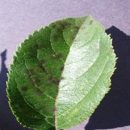
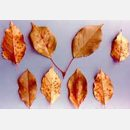
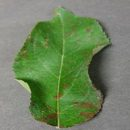
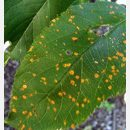
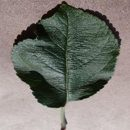
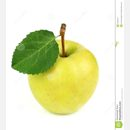
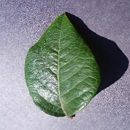
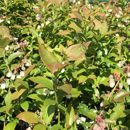
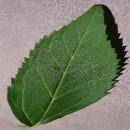
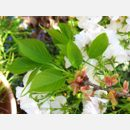
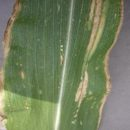
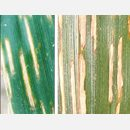
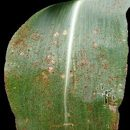
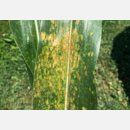
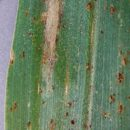
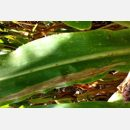
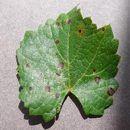
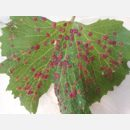
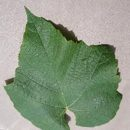
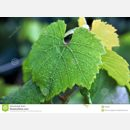
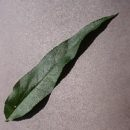
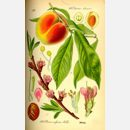
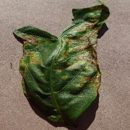
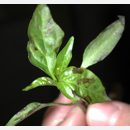
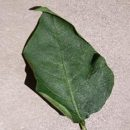
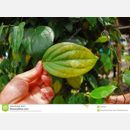
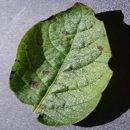
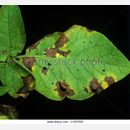
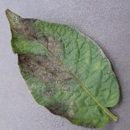
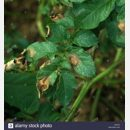
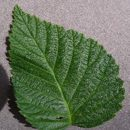
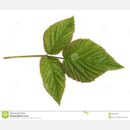
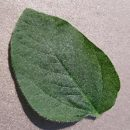
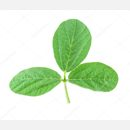
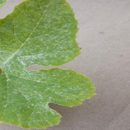
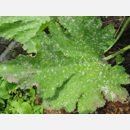
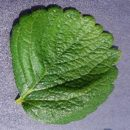
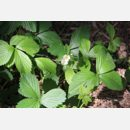
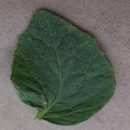
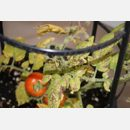
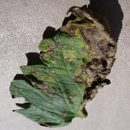
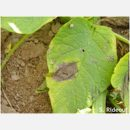
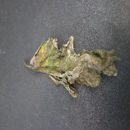
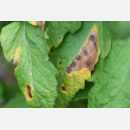
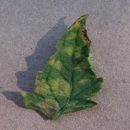
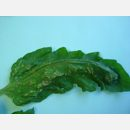
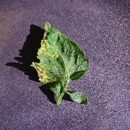
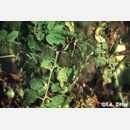
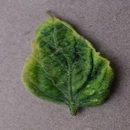
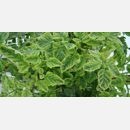
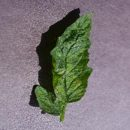
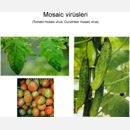
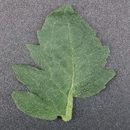
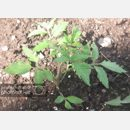

In [ ]:
from collections import defaultdict
from io import BytesIO
import base64
import html
import random
from PIL import Image as PILImage
from IPython.display import HTML, display

pv_paths_by_label = defaultdict(list)
for row in pv_files.itertuples(index=False):
    pv_paths_by_label[row.class_label].append(row.path)

pd_paths_by_label = defaultdict(list)
for row in pd_files.itertuples(index=False):
    pd_paths_by_label[row.class_label].append((row.path, row.split))

class_map_by_name = {
    name: {"PlantVillage": pv_label, "PlantDoc": pd_label}
    for name, pv_label, pd_label in class_map
}


def _image_cell(path, label, split_name, rng, width):
    if path is None:
        return '<span style="color:#666">No mapped folder</span>'
    try:
        with PILImage.open(path) as opened:
            image = opened.convert("RGB")
            image.thumbnail((width, width))
            canvas = PILImage.new("RGB", (width, width), "#f2f2f2")
            x = (width - image.width) // 2
            y = (width - image.height) // 2
            canvas.paste(image, (x, y))
            buffer = BytesIO()
            canvas.save(buffer, format="JPEG", quality=82)
    except Exception as exc:
        return f'<span style="color:#a00">Could not read image: {html.escape(str(exc))}</span>'
    encoded = base64.b64encode(buffer.getvalue()).decode("ascii")
    safe_label = html.escape(str(label))
    safe_split = html.escape(str(split_name))
    return (f'<img src="data:image/jpeg;base64,{encoded}" '
            f'style="width:{width}px;height:{width}px;object-fit:contain">'
            f'<br><small>{safe_label}<br>{safe_split}</small>')


def show_github_image_table(class_names=None, seed=7, image_width=130):
    """Display same-row sample thumbnails read from the local dataset folders."""
    names = list(class_map_by_name) if class_names is None else list(class_names)
    unknown = [name for name in names if name not in class_map_by_name]
    if unknown:
        raise ValueError(f"Unknown class name(s): {unknown}. Choose from {list(class_map_by_name)}")

    rows = []
    for name in names:
        mapping = class_map_by_name[name]
        review_note = " (needs confirmation)" if name in mapping_questions else ""
        pv_label, pd_label = mapping["PlantVillage"], mapping["PlantDoc"]
        rng = random.Random(f"{seed}:{name}")
        pv_choices = pv_paths_by_label.get(pv_label, [])
        pd_choices = pd_paths_by_label.get(pd_label, []) if pd_label else []
        pv_path = rng.choice(pv_choices) if pv_choices else None
        pd_path, pd_split = rng.choice(pd_choices) if pd_choices else (None, "")
        pv_cell = _image_cell(pv_path, pv_label, "raw/color", rng, image_width)
        pd_cell = _image_cell(pd_path, pd_label, pd_split, rng, image_width)
        rows.append(
            "<tr>"
            f'<th style="text-align:left;vertical-align:middle;padding:8px">{html.escape(name + review_note)}</th>'
            f'<td style="text-align:center;padding:8px">{pv_cell}</td>'
            f'<td style="text-align:center;padding:8px">{pd_cell}</td>'
            "</tr>"
        )

    table = (
        '<div style="max-height:750px;overflow:auto"><table style="border-collapse:collapse;width:100%">'
        '<caption>Proposed pairs for inspection; final experiment categories are pending.</caption>'
        '<thead><tr><th style="text-align:left;padding:8px">Class</th>'
        '<th style="padding:8px">PlantVillage Image</th>'
        '<th style="padding:8px">PlantDoc Image</th></tr></thead>'
        + "<tbody>" + "".join(rows) + "</tbody></table></div>"
    )
    display(HTML(table))

# Show all requested classes. For a smaller table, pass a list of class names.
# show_github_image_table(class_names=["Apple Scab", "Tomato Healthy"])
show_github_image_table()
